In [1]:

import os
import zipfile
import shutil
import random
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from google.colab import files
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from sklearn.metrics import classification_report, confusion_matrix

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
print("Available devices:")
for device in tf.config.list_physical_devices():
    print(device)

Available devices:
PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')
PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')


In [5]:
uploaded = files.upload()

print("Uploaded files:")
for filename in uploaded:
    print(filename)

Saving leaf.zip to leaf.zip
Saving non leaf.zip to non leaf.zip
Uploaded files:
leaf.zip
non leaf.zip


In [6]:
import os
import zipfile
import shutil

LEAF_ZIP = "/content/leaf.zip"
NOT_LEAF_ZIP = "/content/non leaf.zip"

DATA_DIR = "/content/leaf_dataset"
TEMP_DIR = "/content/temp_images"

assert os.path.exists(LEAF_ZIP), "leaf.zip not found. Upload it first."
assert os.path.exists(NOT_LEAF_ZIP), "non leaf.zip not found. Upload it first."

shutil.rmtree(DATA_DIR, ignore_errors=True)
shutil.rmtree(TEMP_DIR, ignore_errors=True)

os.makedirs(DATA_DIR + "/leaf")
os.makedirs(DATA_DIR + "/not_leaf")
os.makedirs(TEMP_DIR)

with zipfile.ZipFile(LEAF_ZIP, "r") as z:
    z.extractall(TEMP_DIR + "/leaf")

with zipfile.ZipFile(NOT_LEAF_ZIP, "r") as z:
    z.extractall(TEMP_DIR + "/not_leaf")

print("Both ZIP files extracted successfully!")
print("Both ZIP files extracted.")

Both ZIP files extracted successfully!
Both ZIP files extracted.


In [7]:
from PIL import Image

IMAGE_EXTENSIONS = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

def copy_images(source, destination):
    count = 0

    for root, dirs, filenames in os.walk(source):
        for filename in filenames:
            if filename.lower().endswith(IMAGE_EXTENSIONS):
                src = os.path.join(root, filename)
                dst = os.path.join(
                    destination, f"image_{count:05d}.jpg"
                )

                try:
                    with Image.open(src) as img:
                        img.convert("RGB").save(dst, "JPEG")
                    count += 1
                except Exception as e:
                    print("Skipped unreadable image:", filename)

    return count

leaf_count = copy_images(
    TEMP_DIR + "/leaf",
    DATA_DIR + "/leaf"
)

not_leaf_count = copy_images(
    TEMP_DIR + "/not_leaf",
    DATA_DIR + "/not_leaf"
)

print("Leaf images:", leaf_count)
print("Non-leaf images:", not_leaf_count)

assert leaf_count > 0, "No leaf images were found."
assert not_leaf_count > 0, "No non-leaf images were found."

/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


Skipped unreadable image: 100000006.jpg
Leaf images: 1019
Non-leaf images: 963


In [8]:
import random

random.seed(42)

SPLIT_DIR = "/content/split_dataset"
shutil.rmtree(SPLIT_DIR, ignore_errors=True)

for split in ["train", "val"]:
    for label in ["leaf", "not_leaf"]:
        os.makedirs(
            os.path.join(SPLIT_DIR, split, label),
            exist_ok=True
        )

for label in ["leaf", "not_leaf"]:
    source = os.path.join(DATA_DIR, label)
    images = [
        f for f in os.listdir(source)
        if f.lower().endswith(IMAGE_EXTENSIONS)
    ]

    random.shuffle(images)
    split_index = int(len(images) * 0.8)

    for filename in images[:split_index]:
        shutil.copy2(
            os.path.join(source, filename),
            os.path.join(SPLIT_DIR, "train", label, filename)
        )

    for filename in images[split_index:]:
        shutil.copy2(
            os.path.join(source, filename),
            os.path.join(SPLIT_DIR, "val", label, filename)
        )

print("Dataset split completed!")

Dataset split completed!


In [9]:
import tensorflow as tf

IMG_SIZE = (160, 160)
BATCH_SIZE = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    SPLIT_DIR + "/train",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=True,
    seed=42
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    SPLIT_DIR + "/val",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=False
)

print("Class order:", train_ds.class_names)

Found 1585 files belonging to 2 classes.
Found 397 files belonging to 2 classes.
Class order: ['leaf', 'not_leaf']


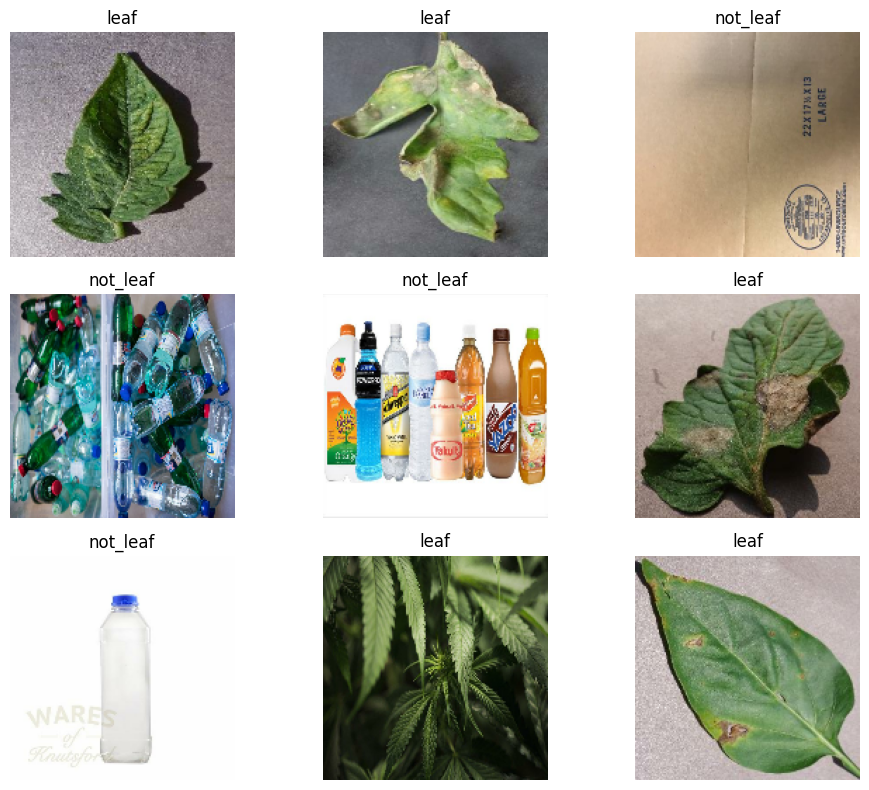

In [10]:
plt.figure(figsize=(10, 8))

for images, labels in train_ds.take(1):
    for i in range(min(9, len(images))):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))

        label = int(labels[i].numpy()[0])
        class_name = train_ds.class_names[label]

        plt.title(class_name)
        plt.axis("off")

plt.tight_layout()
plt.show()

In [11]:

import tensorflow as tf
from tensorflow.keras import layers, models

model = models.Sequential([
    layers.Input(shape=(160, 160, 3)),

    # Normalize pixel values from 0-255 to 0-1
    layers.Rescaling(1./255),

    # First convolution block
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Second convolution block
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Third convolution block
    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Classification layers
    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.4),
    layers.Dense(1, activation="sigmoid")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 158, 158, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 79, 79, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 77, 77, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 38, 38, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 36, 36, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 18, 18, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 41472)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     5,308,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,401,921 (20.61 MB)

 Trainable params: 5,401,921 (20.61 MB)

 Non-trainable params: 0 (0.00 B)

In [12]:

import tensorflow as tf

early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=30,
    callbacks=[early_stop]
)


Epoch 1/30
50/50 ━━━━━━━━━━━━━━━━━━━━ 20s 225ms/step - accuracy: 0.7987 - loss: 0.4578 - val_accuracy: 0.8741 - val_loss: 0.3334
Epoch 2/30
50/50 ━━━━━━━━━━━━━━━━━━━━ 3s 63ms/step - accuracy: 0.9420 - loss: 0.2037 - val_accuracy: 0.9345 - val_loss: 0.1979
Epoch 3/30
50/50 ━━━━━━━━━━━━━━━━━━━━ 3s 62ms/step - accuracy: 0.9552 - loss: 0.1389 - val_accuracy: 0.9118 - val_loss: 0.2584
Epoch 4/30
50/50 ━━━━━━━━━━━━━━━━━━━━ 5s 90ms/step - accuracy: 0.9476 - loss: 0.1461 - val_accuracy: 0.9295 - val_loss: 0.2415
Epoch 5/30
50/50 ━━━━━━━━━━━━━━━━━━━━ 3s 63ms/step - accuracy: 0.9584 - loss: 0.1255 - val_accuracy: 0.9320 - val_loss: 0.1744
Epoch 6/30
50/50 ━━━━━━━━━━━━━━━━━━━━ 3s 62ms/step - accuracy: 0.9584 - loss: 0.1243 - val_accuracy: 0.9446 - val_loss: 0.1854
Epoch 7/30
50/50 ━━━━━━━━━━━━━━━━━━━━ 6s 89ms/step - accuracy: 0.9634 - loss: 0.0951 - val_accuracy: 0.9421 - val_loss: 0.1770
Epoch 8/30
50/50 ━━━━━━━━━━━━━━━━━━━━ 3s 62ms/step - accuracy: 0.9748 - loss: 0.0821 - val_accuracy: 0.9395 -

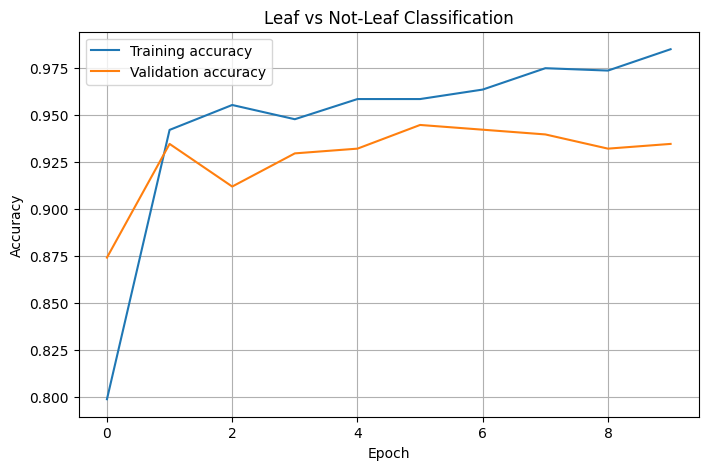

In [13]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Leaf vs Not-Leaf Classification")
plt.legend()
plt.grid(True)
plt.show()

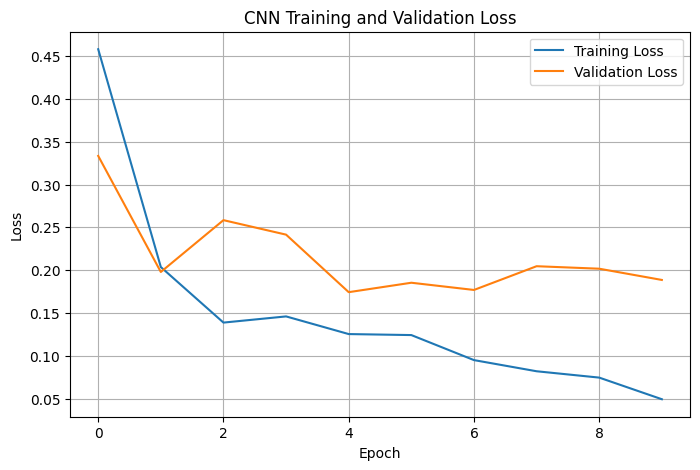

In [14]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

In [15]:
from sklearn.metrics import accuracy_score

y_true = []
y_pred = []

for images, labels in val_ds:
    probabilities = model.predict(images, verbose=0).ravel()

    y_true.extend(labels.numpy().ravel().astype(int))
    y_pred.extend((probabilities >= 0.5).astype(int))

print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=["LEAF", "NOT_LEAF"],
    zero_division=0
))
print("accuracy",accuracy_score(y_true, y_pred))
print("Confusion matrix:")
print(confusion_matrix(y_true, y_pred, labels=[0, 1]))

              precision    recall  f1-score   support

        LEAF       0.93      0.94      0.93       204
    NOT_LEAF       0.93      0.93      0.93       193

    accuracy                           0.93       397
   macro avg       0.93      0.93      0.93       397
weighted avg       0.93      0.93      0.93       397

accuracy 0.9319899244332494
Confusion matrix:
[[191  13]
 [ 14 179]]


Saving images.jpg to images.jpg
Image: images.jpg
Prediction: LEAF
Not-leaf probability: 0.2594


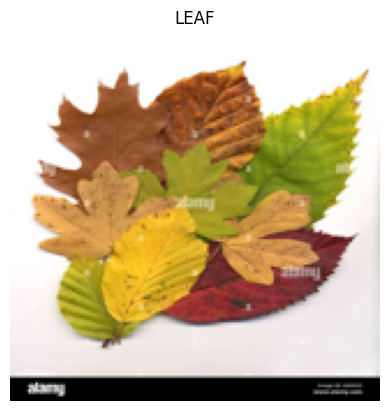

In [16]:
uploaded_test = files.upload()

from PIL import Image

for filename in uploaded_test:
    img = Image.open(filename).convert("RGB")
    img = img.resize(IMG_SIZE)

    image_array = np.array(img, dtype=np.float32)
    image_array = np.expand_dims(image_array, axis=0)

    probability_not_leaf = float(
        model.predict(image_array, verbose=0)[0][0]
    )

    if probability_not_leaf >= 0.5:
        prediction = "NOT_LEAF"
    else:
        prediction = "LEAF"

    print("Image:", filename)
    print("Prediction:", prediction)
    print("Not-leaf probability:", round(probability_not_leaf, 4))

    plt.imshow(img)
    plt.title(prediction)
    plt.axis("off")
    plt.show()

In [17]:
model.save("/content/leaf_classifier.keras")
print("Model saved.")

Model saved.


In [18]:
converter = tf.lite.TFLiteConverter.from_keras_model(model)

# Reduce model size using dynamic-range quantization
converter.optimizations = [tf.lite.Optimize.DEFAULT]

tflite_model = converter.convert()

with open("/content/leaf_classifier.tflite", "wb") as f:
    f.write(tflite_model)

print("TFLite model size:",
      round(os.path.getsize("/content/leaf_classifier.tflite") / 1024, 2),
      "KB")

Saved artifact at '/tmp/tmp67uj0bb9'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 160, 160, 3), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  138535986694480: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138535984997264: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138535984996880: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138535984991312: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138535984992656: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138535985001296: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138535984995536: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138535984997072: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138535985001104: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138535984999760: TensorSpec(shape=(), dtype=tf.resource, name=None)
TFLite model siz

In [19]:
files.download("/content/leaf_classifier.keras")
files.download("/content/leaf_classifier.tflite")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>